<a href="https://colab.research.google.com/github/Wrdone/MH/blob/main/%D0%9B%D0%A011_%D0%9B%D1%83%D0%BA'%D1%8F%D0%BD_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 11

**Виконав:**

**Прізвище** Лук'ян

**група №** 10

**Тема:** Розпізнавання дорожніх знаків за допомогою згорткової нейронної мережі.

**Мета:** Набути практичних навичок побудови, навчання та оцінювання згорткових нейронних мереж для класифікації зображень на основі набору даних GTSRB.


1. Підключення бібліотек

In [ ]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

2. Завантаження GTSRB

In [ ]:
path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Шлях до набору даних:", path)
print(os.listdir(path))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Шлях до набору даних: /kaggle/input/gtsrb-german-traffic-sign
['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


3. Виведення дорожніх знаків

          Path  ClassId  ShapeId  ColorId SignId
1   Meta/0.png        0        1        0   3.29
2   Meta/1.png        1        1        0   3.29
13  Meta/2.png        2        1        0   3.29
23  Meta/3.png        3        1        0   3.29
34  Meta/4.png        4        1        0   3.29
Кількість класів: 43


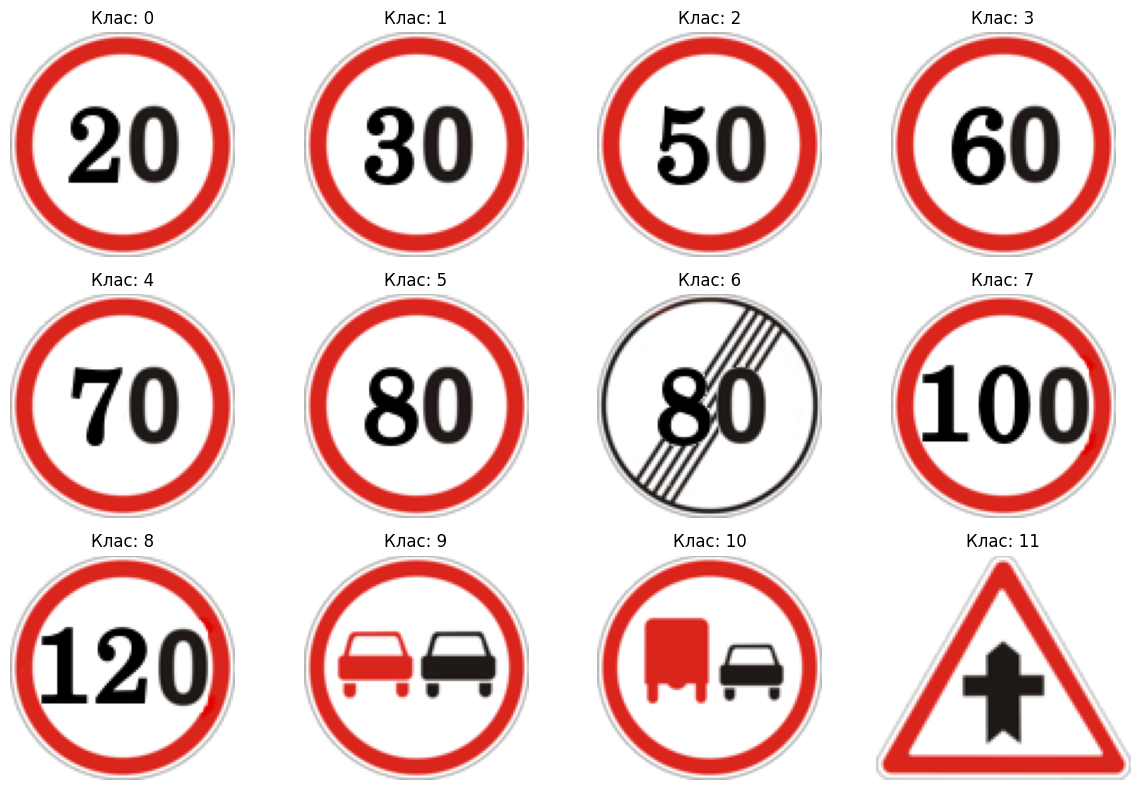

In [ ]:
meta = pd.read_csv(os.path.join(path, "Meta.csv"))
meta = meta.sort_values("ClassId")

print(meta.head())
print("Кількість класів:", meta["ClassId"].nunique())

plt.figure(figsize=(12, 8))

for i in range(12):
    row = meta.iloc[i]
    img = plt.imread(os.path.join(path, row["Path"]))

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"Клас: {row['ClassId']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

4. Підготовка навчальних даних

In [ ]:
IMG_SIZE = (32, 32)
BATCH_SIZE = 64

train_path = os.path.join(path, "Train")

class_names = [str(i) for i in range(43)]

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

Found 39209 files belonging to 43 classes.
Using 31368 files for training.
Found 39209 files belonging to 43 classes.
Using 7841 files for validation.


5. Побудова згорткової нейронної мережі

In [ ]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(43, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,067 (1.38 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

6. Навчання нейронної мережі

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 118s 222ms/step - accuracy: 0.3610 - loss: 2.2305 - val_accuracy: 0.6734 - val_loss: 1.0775
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.7504 - loss: 0.7708 - val_accuracy: 0.9133 - val_loss: 0.2960
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.8896 - loss: 0.3492 - val_accuracy: 0.9713 - val_loss: 0.1197
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.9336 - loss: 0.2104 - val_accuracy: 0.9813 - val_loss: 0.0765
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 41s 43ms/step - accuracy: 0.9540 - loss: 0.1455 - val_accuracy: 0.9828 - val_loss: 0.0590
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.9603 - loss: 0.1247 - val_accuracy: 0.9903 - val_loss: 0.0444
Epoch 7/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.9709 - loss: 0.0886 - val_accuracy: 0.9915 - val_loss: 0.0351
Epoch 8/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 21s 42ms/step - accuracy: 0.9749 - loss: 0.0779 

7. Побудова кривих навчання

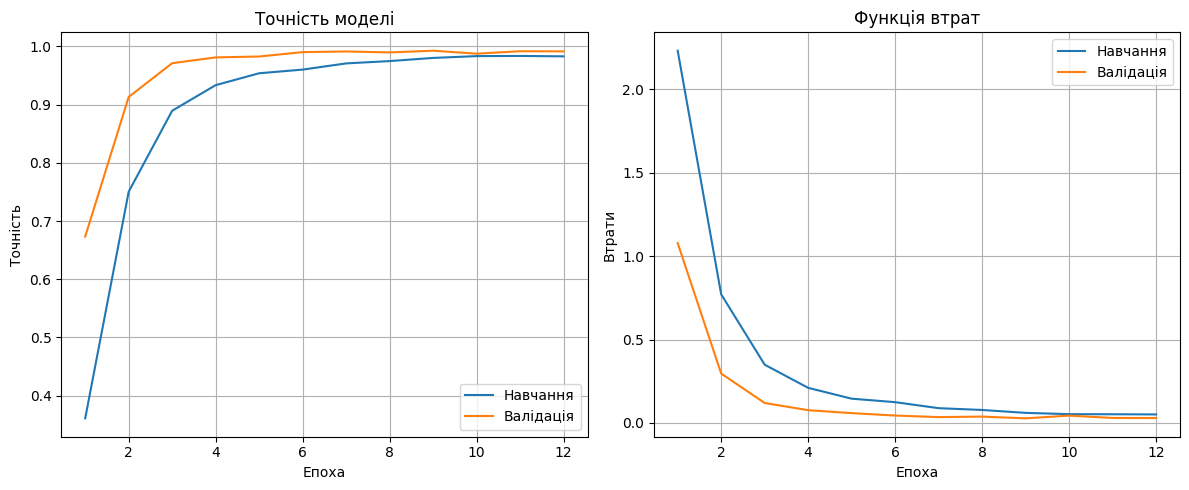

In [ ]:
plt.figure(figsize=(12, 5))

epochs = range(1, len(history.history["accuracy"]) + 1)

plt.subplot(1, 2, 1)
plt.plot(epochs, history.history["accuracy"],
         label="Навчання")
plt.plot(epochs, history.history["val_accuracy"],
         label="Валідація")

plt.title("Точність моделі")
plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(epochs, history.history["loss"],
         label="Навчання")
plt.plot(epochs, history.history["val_loss"],
         label="Валідація")

plt.title("Функція втрат")
plt.xlabel("Епоха")
plt.ylabel("Втрати")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

8. Підготовка тестових даних

In [ ]:
test_df = pd.read_csv(os.path.join(path, "Test.csv"))

X_test = []
y_test = []

for _, row in test_df.iterrows():
    img_path = os.path.join(path, row["Path"])

    img = tf.keras.utils.load_img(
    img_path,
    target_size=(32, 32),
    interpolation="bilinear"
    )

    img = tf.keras.utils.img_to_array(img)

    X_test.append(img)
    y_test.append(row["ClassId"])

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Кількість тестових зображень:", len(X_test))

Кількість тестових зображень: 12630


9. Оцінювання точності моделі

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test
)

print(f"Точність моделі: {test_accuracy * 100:.2f}%")
print(f"Функція втрат: {test_loss:.4f}")

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9470 - loss: 0.2391
Точність моделі: 94.70%
Функція втрат: 0.2391


10. Візуалізація результатів класифікації

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


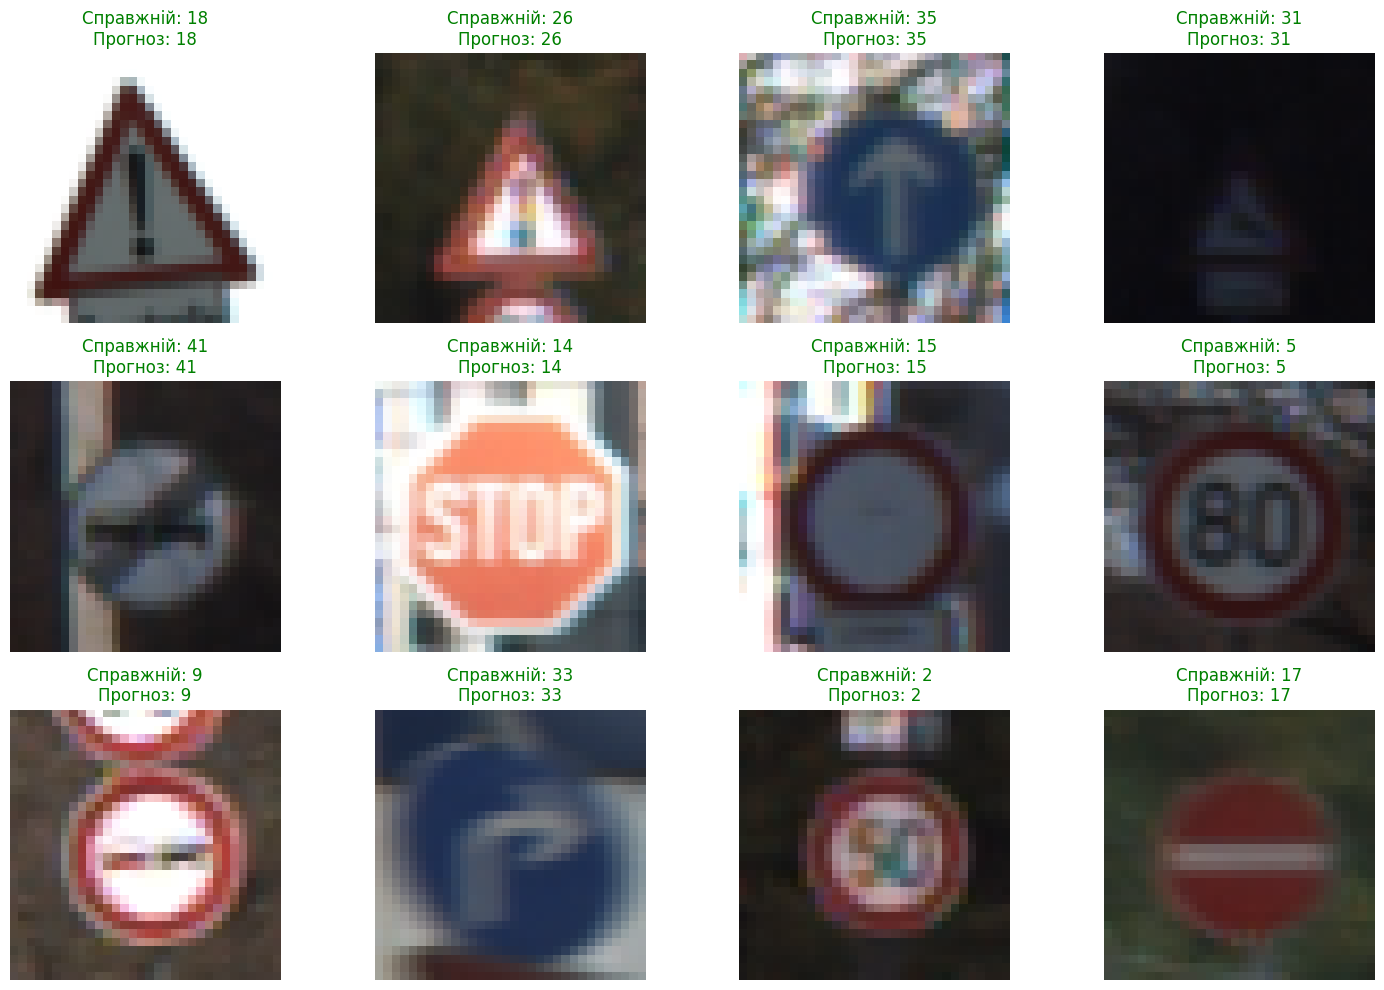

In [ ]:
predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(15, 10))

indices = np.random.choice(
    len(X_test), 12, replace=False
)

for i, index in enumerate(indices):
    true_class = y_test[index]
    predicted_class = predicted_classes[index]

    color = (
        "green" if true_class == predicted_class
        else "red"
    )

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[index].astype("uint8"))

    plt.title(
        f"Справжній: {true_class}\n"
        f"Прогноз: {predicted_class}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

11. **Висновок**

У ході виконання лабораторної роботи було розроблено згорткову нейронну мережу для розпізнавання дорожніх знаків на основі набору даних GTSRB, який містить 43 класи дорожніх знаків.

Було виконано завантаження, візуалізацію та попередню обробку зображень із приведенням їх до розміру 32×32 пікселі. Побудовано архітектуру нейронної мережі з використанням згорткових і повнозв'язних шарів, шарів субдискретизації та Dropout.

Навчання моделі завершилося на 12-й епосі завдяки використанню механізму EarlyStopping. Найкраща точність на валідаційних даних становила 99,27%. За результатами тестування моделі на незалежному наборі з 12 630 зображень було отримано точність 94,70% та значення функції втрат 0,2391.

Було побудовано графіки зміни точності та функції втрат, а також виконано візуалізацію результатів класифікації із зазначенням справжніх і прогнозованих класів. Усі 12 випадково обраних зображень було класифіковано правильно.